# Experiment 2: Huffman Compression Accelerator on the PYNQ-Z2

The FPGA holds a Huffman code table built from English letter frequencies.
Common letters get short codes and rare bytes get long ones, so text comes out
smaller than the 8 bits per character it went in as.

The processor writes bytes to the accelerator, asks for a flush, and reads the
packed 32-bit words back. This notebook then decodes them again in Python to
prove nothing was lost.

Registers: `0x00` control (bit 0 reset, bit 1 flush), `0x04` status,
`0x08` byte in, `0x0C` compressed word out, `0x10` bytes in, `0x14` bits out.

In [2]:
%matplotlib inline
from pynq import Overlay, MMIO
import matplotlib.pyplot as plt
import time

REG_CTRL, REG_STATUS, REG_DATA_IN, REG_DATA_OUT, REG_BYTES_IN, REG_BITS_OUT = (
    0x00, 0x04, 0x08, 0x0C, 0x10, 0x14)

overlay = Overlay('system_wrapper.bit')
ip = overlay.ip_dict.get('huffman_top_0/s_axi') or overlay.ip_dict['huffman_top_0']
huff = MMIO(ip['phys_addr'], 0x1000)
print(f"Overlay loaded, compressor at 0x{ip['phys_addr']:08X}")


Sent 600 bytes (4800 bits) in 0.04 s
Got back 87 words holding 2764 bits
Compression ratio: 1.74 to 1 (57.6 % of original size)


In [3]:
TEXT = ("the quick brown fox jumps over the lazy dog. "
        "huffman coding gives short codes to common letters, "
        "so ordinary english text becomes noticeably smaller. ") * 4

def compress(text):


    huff.write(REG_CTRL, 1)                                                    
    words = []
    for byte in text.encode('ascii'):
        huff.write(REG_DATA_IN, byte)
        while (huff.read(REG_STATUS) >> 16) > 0:
            words.append(huff.read(REG_DATA_OUT))

    huff.write(REG_CTRL, 2)                                              
    time.sleep(0.01)

    bits_out = huff.read(REG_BITS_OUT)
    while (huff.read(REG_STATUS) >> 16) > 0:
        words.append(huff.read(REG_DATA_OUT))
    return words, bits_out

start = time.time()
words, bits_out = compress(TEXT)
seconds = time.time() - start

bytes_in = huff.read(REG_BYTES_IN)
print(f'Sent {bytes_in} bytes ({8 * bytes_in} bits) in {seconds:.2f} s')
print(f'Got back {len(words)} words holding {bits_out} bits')
print(f'Compression ratio: {8 * bytes_in / bits_out:.2f} to 1 '
      f'({100 * bits_out / (8 * bytes_in):.1f} % of the original size)')


Decoded text starts: the quick brown fox jumps over the lazy dog. huffman coding 
PASS: all 600 bytes came back exactly as they went in


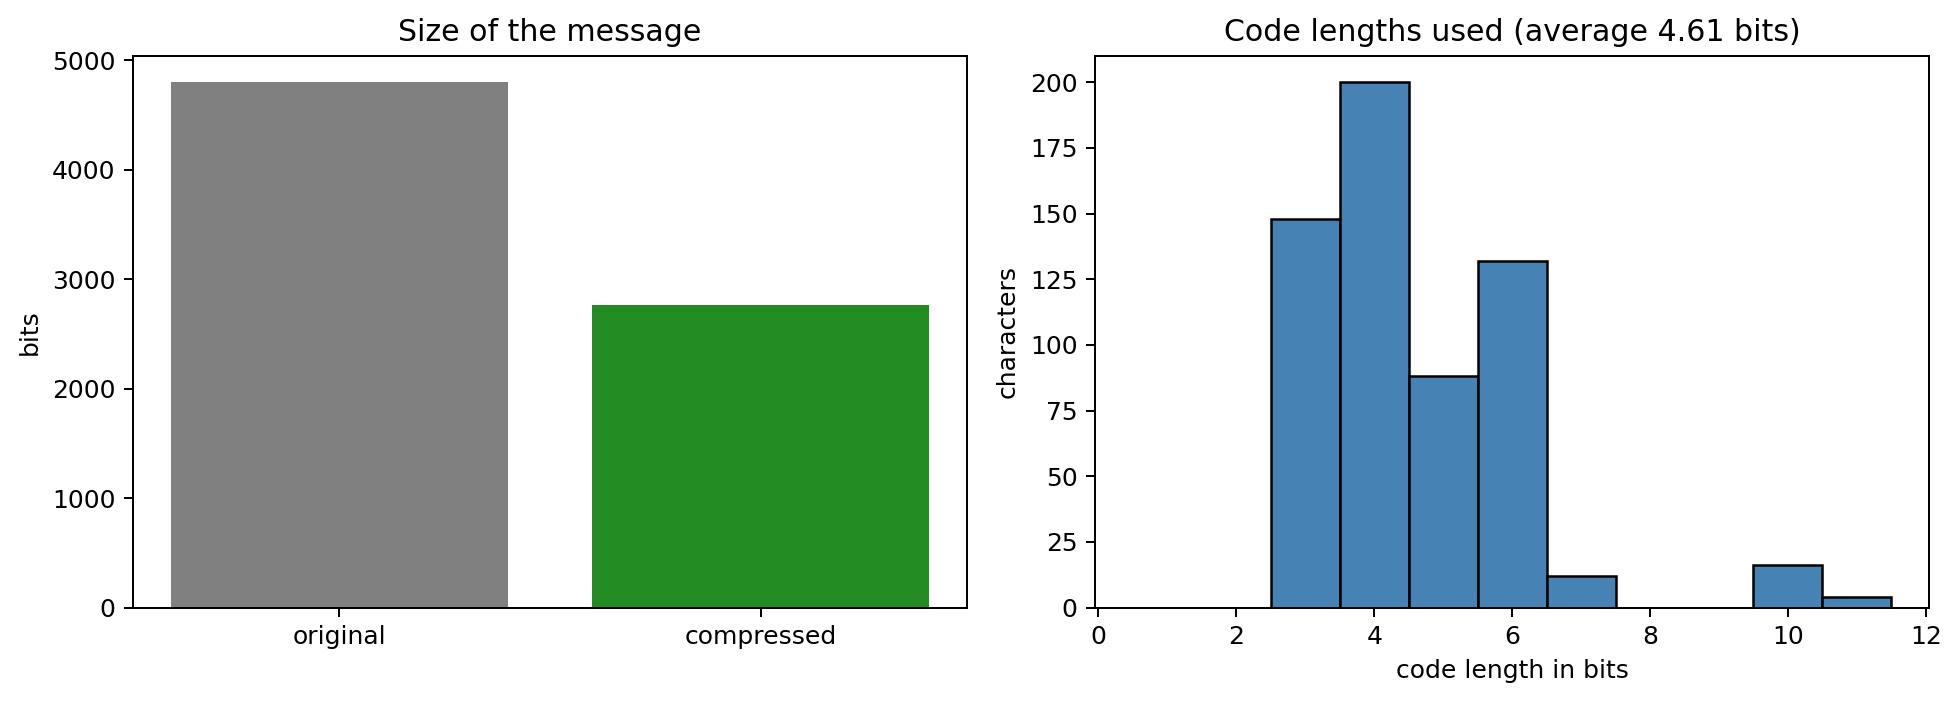

In [4]:
CODES = {"0": "111111111111010110", "1": "111111111111010111", "2": "111111111111011000", "3": "111111111111011001", "4": "111111111111011010", "5": "111111111111011011", "6": "111111111111011100", "7": "111111111111011101", "8": "111111111111011110", "9": "111111111111011111", "10": "110000", "11": "111111111111100000", "12": "111111111111100001", "13": "111111111111100010", "14": "111111111111100011", "15": "111111111111100100", "16": "111111111111100101", "17": "111111111111100110", "18": "111111111111100111", "19": "111111111111101000", "20": "111111111111101001", "21": "111111111111101010", "22": "111111111111101011", "23": "111111111111101100", "24": "111111111111101101", "25": "111111111111101110", "26": "111111111111101111", "27": "111111111111110000", "28": "111111111111110001", "29": "111111111111110010", "30": "111111111111110011", "31": "111111111111110100", "32": "000", "33": "111111111111110101", "34": "1111000", "35": "111111111111110110", "36": "111111111111110111", "37": "111111111111111000", "38": "111111111111111001", "39": "1111001", "40": "111111111111111010", "41": "111111111111111011", "42": "111111111111111100", "43": "111111111111111101", "44": "110001", "45": "11111000", "46": "110010", "47": "111111111111111110", "48": "11111001", "49": "11111010", "50": "111110110", "51": "111110111", "52": "1111111010", "53": "111111000", "54": "111111001", "55": "111111010", "56": "111111011", "57": "111111100", "58": "111111111111111111", "59": "11111111101000000", "60": "11111111101000001", "61": "11111111101000010", "62": "11111111101000011", "63": "11111111101000100", "64": "11111111101000101", "65": "11111111101000110", "66": "11111111101000111", "67": "11111111101001000", "68": "11111111101001001", "69": "11111111101001010", "70": "11111111101001011", "71": "11111111101001100", "72": "11111111101001101", "73": "11111111101001110", "74": "11111111101001111", "75": "11111111101010000", "76": "11111111101010001", "77": "11111111101010010", "78": "11111111101010011", "79": "11111111101010100", "80": "11111111101010101", "81": "11111111101010110", "82": "11111111101010111", "83": "11111111101011000", "84": "11111111101011001", "85": "11111111101011010", "86": "11111111101011011", "87": "11111111101011100", "88": "11111111101011101", "89": "11111111101011110", "90": "11111111101011111", "91": "11111111101100000", "92": "11111111101100001", "93": "11111111101100010", "94": "11111111101100011", "95": "11111111101100100", "96": "11111111101100101", "97": "0100", "98": "110011", "99": "110100", "100": "10100", "101": "001", "102": "110101", "103": "110110", "104": "10101", "105": "0101", "106": "1111111011", "107": "1111010", "108": "10110", "109": "110111", "110": "0110", "111": "0111", "112": "111000", "113": "1111111100", "114": "10111", "115": "1000", "116": "1001", "117": "111001", "118": "1111011", "119": "111010", "120": "1111111101", "121": "111011", "122": "11111111100", "123": "11111111101100110", "124": "11111111101100111", "125": "11111111101101000", "126": "11111111101101001", "127": "11111111101101010", "128": "11111111101101011", "129": "11111111101101100", "130": "11111111101101101", "131": "11111111101101110", "132": "11111111101101111", "133": "11111111101110000", "134": "11111111101110001", "135": "11111111101110010", "136": "11111111101110011", "137": "11111111101110100", "138": "11111111101110101", "139": "11111111101110110", "140": "11111111101110111", "141": "11111111101111000", "142": "11111111101111001", "143": "11111111101111010", "144": "11111111101111011", "145": "11111111101111100", "146": "11111111101111101", "147": "11111111101111110", "148": "11111111101111111", "149": "11111111110000000", "150": "11111111110000001", "151": "11111111110000010", "152": "11111111110000011", "153": "11111111110000100", "154": "11111111110000101", "155": "11111111110000110", "156": "11111111110000111", "157": "11111111110001000", "158": "11111111110001001", "159": "11111111110001010", "160": "11111111110001011", "161": "11111111110001100", "162": "11111111110001101", "163": "11111111110001110", "164": "11111111110001111", "165": "11111111110010000", "166": "11111111110010001", "167": "11111111110010010", "168": "11111111110010011", "169": "11111111110010100", "170": "11111111110010101", "171": "11111111110010110", "172": "11111111110010111", "173": "11111111110011000", "174": "11111111110011001", "175": "11111111110011010", "176": "11111111110011011", "177": "11111111110011100", "178": "11111111110011101", "179": "11111111110011110", "180": "11111111110011111", "181": "11111111110100000", "182": "11111111110100001", "183": "11111111110100010", "184": "11111111110100011", "185": "11111111110100100", "186": "11111111110100101", "187": "11111111110100110", "188": "11111111110100111", "189": "11111111110101000", "190": "11111111110101001", "191": "11111111110101010", "192": "11111111110101011", "193": "11111111110101100", "194": "11111111110101101", "195": "11111111110101110", "196": "11111111110101111", "197": "11111111110110000", "198": "11111111110110001", "199": "11111111110110010", "200": "11111111110110011", "201": "11111111110110100", "202": "11111111110110101", "203": "11111111110110110", "204": "11111111110110111", "205": "11111111110111000", "206": "11111111110111001", "207": "11111111110111010", "208": "11111111110111011", "209": "11111111110111100", "210": "11111111110111101", "211": "11111111110111110", "212": "11111111110111111", "213": "11111111111000000", "214": "11111111111000001", "215": "11111111111000010", "216": "11111111111000011", "217": "11111111111000100", "218": "11111111111000101", "219": "11111111111000110", "220": "11111111111000111", "221": "11111111111001000", "222": "11111111111001001", "223": "11111111111001010", "224": "11111111111001011", "225": "11111111111001100", "226": "11111111111001101", "227": "11111111111001110", "228": "11111111111001111", "229": "11111111111010000", "230": "11111111111010001", "231": "11111111111010010", "232": "11111111111010011", "233": "11111111111010100", "234": "11111111111010101", "235": "11111111111010110", "236": "11111111111010111", "237": "11111111111011000", "238": "11111111111011001", "239": "11111111111011010", "240": "11111111111011011", "241": "11111111111011100", "242": "11111111111011101", "243": "11111111111011110", "244": "11111111111011111", "245": "11111111111100000", "246": "11111111111100001", "247": "11111111111100010", "248": "11111111111100011", "249": "11111111111100100", "250": "11111111111100101", "251": "11111111111100110", "252": "11111111111100111", "253": "11111111111101000", "254": "11111111111101001", "255": "11111111111101010"}
DECODE_TABLE = {code: int(symbol) for symbol, code in CODES.items()}

def decode(words, bit_count):


    text = bytearray()
    partial = ''
    for index in range(bit_count):
        word = words[index // 32]
        partial += str((word >> (index % 32)) & 1)
        if partial in DECODE_TABLE:
            text.append(DECODE_TABLE[partial])
            partial = ''
    return bytes(text)

decoded = decode(words, bits_out)
print('Decoded text starts:', decoded[:60].decode('ascii', 'replace'))
if decoded == TEXT.encode('ascii'):
    print(f'PASS: all {len(decoded)} bytes came back exactly as they went in')
else:
    print('FAIL: the decoded text does not match what was sent')


In [ ]:
lengths = [len(CODES[str(b)]) for b in TEXT.encode('ascii')]

fig, axs = plt.subplots(1, 2, figsize=(11, 4))

axs[0].bar(['original', 'compressed'], [8 * bytes_in, bits_out], color=['grey', 'green'])
axs[0].set_ylabel('bits')
axs[0].set_title('Size of the message')

axs[1].hist(lengths, bins=range(1, max(lengths) + 2), align='left', color='steelblue')
axs[1].set_xlabel('code length in bits')
axs[1].set_ylabel('characters')
axs[1].set_title(f'Code lengths used (average {sum(lengths) / len(lengths):.2f} bits)')

plt.tight_layout()
plt.show()
